# SIS Analysis - Data Processing

**Objective**: Load raw environmental data (Shapefiles), clean/process it, and save to a merged Feather file for efficient analysis.

**Refactored from**: `analysis5.ipynb`

In [1]:
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("../../").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data
from utils.paths import ProjectPaths
import pandas as pd

print("Project Root:", project_root)

Project Root: /home/reyha/SIS_Analysis_WSL


In [2]:
# Analysis Inspection Parameters
target_season = 'Summer'
target_layer = 2

## Load and Process Data
This step checks for `data/processed/merged_gdf.feather`. If missing, it loads all raw shapefiles from `data/raw/environmental_data/`.

In [3]:
# Set force_reload=True if you added new raw data or changed the cleaning logic
merged_gdf = load_and_process_data(force_reload=True)

print("Data Shape:", merged_gdf.shape)
merged_gdf.info()

Loading raw shapefiles from 1981 to 2023...
Merging 171 shapefiles...
Processing data (detecting V2 parameters, cleaning DO, adding seasons)...
Mapped ph2 -> ph (ph2: 62738 valid float entries | ph: 62480 valid originally)
Mapped do_2 -> do_ (do_2: 62738 valid float entries | do_: 62472 valid originally)
Mapped salt2 -> salt (salt2: 62738 valid float entries | salt: 59945 valid originally)
Mapped cod2 -> cod (cod2: 62738 valid float entries | cod: 62336 valid originally)
Mapped rcod2 -> rcod (rcod2: 62738 valid float entries | rcod: 31889 valid originally)
Mapped nh4n2 -> nh4n (nh4n2: 62738 valid float entries | nh4n: 59605 valid originally)
Mapped no2n2 -> no2n (no2n2: 62738 valid float entries | no2n: 59360 valid originally)
Mapped no3n2 -> no3n (no3n2: 62738 valid float entries | no3n: 59865 valid originally)
Mapped tn2 -> tn (tn2: 62738 valid float entries | tn: 62211 valid originally)
Mapped po4p2 -> po4p (po4p2: 62738 valid float entries | po4p: 59483 valid originally)
Mapped tp2

In [4]:
# Filter data for inspection using parameters
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == target_season) & 
    (merged_gdf['saisuipoin'] == target_layer)
].dropna(subset=['do_']).copy()

# Convert do_ to numeric
summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')

# Inspect the dataset.

In [5]:
# --- STEP 1: Select Target for Inspection ---
# Assign the dataframe you want to analyze to 'df_to_inspect'
df_to_inspect = summer_bottom_df
print(f"Target DataFrame selected. Shape: {df_to_inspect.shape}")

# --- General Info ---
print("--- Data Info ---")
df_to_inspect.info()
print("\n--- First 5 Rows ---")
display(df_to_inspect.head())
print("\n--- Last 5 Rows ---")
display(df_to_inspect.tail())

Target DataFrame selected. Shape: (8033, 65)
--- Data Info ---
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 8033 entries, 2 to 62709
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        8033 non-null   object        
 1   zettaicode      8033 non-null   object        
 2   locationna      8033 non-null   object        
 3   wancode         8033 non-null   object        
 4   prefectuei      8033 non-null   object        
 5   watercode       8033 non-null   int64         
 6   renban          8033 non-null   object        
 7   nendo           8033 non-null   int64         
 8   survey_ym       8033 non-null   datetime64[ms]
 9   surveyyear      8033 non-null   int64         
 10  surveymont      8033 non-null   int64         
 11  surveyday       8033 non-null   int64         
 12  surveyhour      8033 non-null   int64         
 13  surveymini      8033 non-null   int64    

,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
2,0000001518,00002353,愛知県53,02,23,200,53,1981,1981-06-01,1981,...,0.0,0.0,1,-1,POINT (137.11861 34.77667),1981,Ise Bay,—,—,Summer
7,0000001494,00002343,愛知県43,02,23,200,43,1981,1981-06-01,1981,...,0.0,0.0,1,-1,POINT (136.99694 34.58),1981,Ise Bay,—,—,Summer
16,0000001446,00002317,愛知県17,02,23,200,17,1981,1981-06-01,1981,...,0.0,0.0,1,-1,POINT (136.83028 34.83),1981,Ise Bay,—,—,Summer
24,0000001454,00002321,愛知県21,02,23,200,21,1981,1981-06-01,1981,...,0.0,0.0,1,-1,POINT (136.80194 34.77667),1981,Ise Bay,—,—,Summer
32,0000001462,00002325,愛知県25,02,23,200,25,1981,1981-06-01,1981,...,0.0,0.0,1,-1,POINT (136.80194 34.72333),1981,Ise Bay,—,—,Summer



--- Last 5 Rows ---


,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
62701,0000067659,00001432,神奈川県32,01,14,100,32,2023,2023-06-01,2023,...,1.1,1.1,1,-1,POINT (139.74806 35.46083),2023,Tokyo Bay,—,—,Summer
62703,0000067661,00001434,神奈川県34,01,14,100,34,2023,2023-06-01,2023,...,1.0,1.0,1,-1,POINT (139.695 35.41917),2023,Tokyo Bay,—,—,Summer
62705,0000067663,00001439,神奈川県39,01,14,100,39,2023,2023-06-01,2023,...,0.9,0.9,1,-1,POINT (139.75778 35.28556),2023,Tokyo Bay,—,—,Summer
62707,0000067665,00001441,神奈川県41,01,14,100,41,2023,2023-06-01,2023,...,1.0,1.0,1,-1,POINT (139.72167 35.35056),2023,Tokyo Bay,—,—,Summer
62709,0000067667,00001446,神奈川県46,01,14,100,46,2023,2023-06-01,2023,...,0.9,0.9,1,-1,POINT (139.76333 35.22778),2023,Tokyo Bay,—,—,Summer


In [6]:
import pandas as pd

# --- Missing Values Check ---
missing_count = df_to_inspect.isnull().sum()
missing_percent = (missing_count / len(df_to_inspect)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percent
}).sort_values(by='Missing Values', ascending=False)
# Filter to show only columns with missing data
print("--- Columns with Missing Data ---")
display(missing_df[missing_df['Missing Values'] > 0])

--- Columns with Missing Data ---


,Missing Values,Percentage
clearness,5497,68.430225
color,4541,56.529317
fuko,3602,44.840035
fusoku,3002,37.370845
cloud,2854,35.528445
temp,2150,26.764596
weather,1794,22.332877
depth,1160,14.440433
division,389,4.842525
watermass_name,389,4.842525


In [7]:
# --- Statistical Summary (Numeric) ---

# Ensure temperature columns are numeric so they are included in the summary
df_to_inspect['temp'] = pd.to_numeric(df_to_inspect['temp'], errors='coerce')
df_to_inspect['wtemp'] = pd.to_numeric(df_to_inspect['wtemp'], errors='coerce') # Added water temperature as well
df_to_inspect['salt'] = pd.to_numeric(df_to_inspect['salt'], errors='coerce') # Added salinity as well

print("--- Statistics for Numeric Columns ---")
display(df_to_inspect.describe().T) # Transposed for better readability

--- Statistics for Numeric Columns ---


,count,mean,min,25%,50%,75%,max,std
watercode,8033.0,259.039711,100.0,200.0,306.0,313.0,318.0,78.804407
nendo,8033.0,2002.191211,1981.0,1991.0,2002.0,2013.0,2023.0,12.490815
survey_ym,8033,2002-08-09 07:00:11.203000,1981-06-01 00:00:00,1991-06-01 00:00:00,2002-06-01 00:00:00,2013-06-01 00:00:00,2023-06-01 00:00:00,NaN
surveyyear,8033.0,2002.191336,1981.0,1991.0,2002.0,2013.0,2023.0,12.490808
surveymont,8033.0,7.165318,6.0,7.0,7.0,7.0,8.0,0.40083
surveyday,8033.0,14.117764,1.0,9.0,14.0,20.0,30.0,7.087587
surveyhour,8033.0,9.980829,0.0,9.0,10.0,11.0,18.0,2.798536
surveymini,8033.0,27.011702,0.0,10.0,27.0,42.0,59.0,17.941288
saisuipoin,8033.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0
latitude,8033.0,34.377909,32.947778,33.975,34.330833,34.723333,35.647222,0.646225


--- Spatial Distribution of Data Points ---

Map Bounds (MinX, MinY, MaxX, MaxY): [130.8058333   32.94777778 140.0733333   35.64722222]


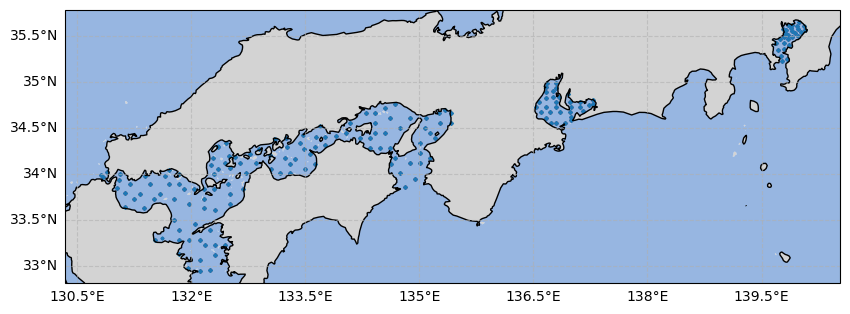

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Quick Spatial Plot ---
if hasattr(df_to_inspect, 'geometry'):
    print("--- Spatial Distribution of Data Points ---")
    
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Add background features
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN)
    ax.add_feature(cfeature.COASTLINE)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.6)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot spatial data
    df_to_inspect.plot(ax=ax, markersize=2, alpha=0.5, transform=ccrs.PlateCarree())
    
    # Check Bounds
    bounds = df_to_inspect.total_bounds
    print(f"\nMap Bounds (MinX, MinY, MaxX, MaxY): {bounds}")
else:
    print("DataFrame does not have a geometry column.")

In [9]:
# === Find out the depth range of both 'saisuipoin' category ===

# Convert 'depth' column to numeric, forcing non-numeric values to NaN (since it is currently Object type)
merged_gdf['depth'] = pd.to_numeric(merged_gdf['depth'], errors='coerce')

# Group by 'saisuipoin' and calculate the minimum and maximum depth
depth_ranges = merged_gdf.groupby('saisuipoin')['depth'].agg(['min', 'max'])

# Display the results
print("Depth ranges for each 'saisuipoin' category:")
print(depth_ranges)

Depth ranges for each 'saisuipoin' category:
            min    max
saisuipoin            
1           0.5  179.0
2           1.1  179.0


--- Spatial Distribution of Data Points ---

Map Bounds (MinX, MinY, MaxX, MaxY): [130.8058333   32.94777778 140.0733333   35.64722222]


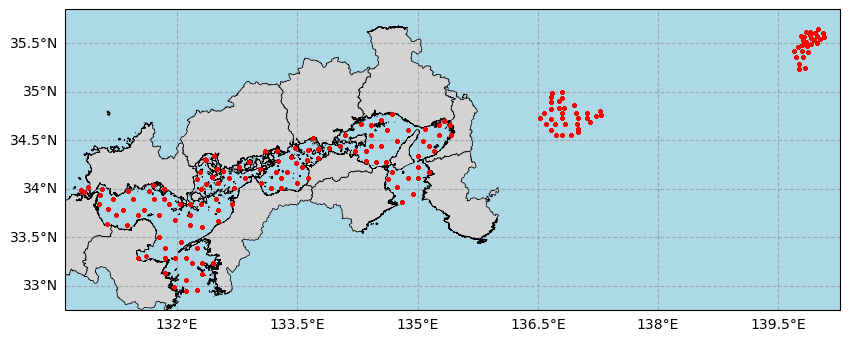

In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from utils.paths import ProjectPaths

# --- Quick Spatial Plot ---
if hasattr(df_to_inspect, 'geometry'):
    print("--- Spatial Distribution of Data Points ---")
    
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # 1. Set the background color to a more visible blue
    # Changed from 'azure' to 'lightblue' so the sea is clearly visible
    ax.set_facecolor('lightblue')
    
    # 2. Load the Setonaikai boundary file
    boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
    sis_boundary = gpd.read_file(boundary_path)
    
    # Ensure it's in WGS84 to match the plot projection
    if sis_boundary.crs != "EPSG:4326":
        sis_boundary = sis_boundary.to_crs("EPSG:4326")
    
    # 3. Plot the detailed SIS boundary as the land/coastline context
    # This overlays the land (lightgray) on top of the lightblue background
    sis_boundary.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot spatial data (survey points)
    df_to_inspect.plot(ax=ax, markersize=3, color='red', alpha=0.8, transform=ccrs.PlateCarree(), zorder=3)
    
    # Optional: Set the extent to tightly fit the data with a small buffer
    bounds = df_to_inspect.total_bounds
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())
    
    print(f"\nMap Bounds (MinX, MinY, MaxX, MaxY): {bounds}")
else:
    print("DataFrame does not have a geometry column.")